# Data


#### Swiss Confederation bond curves for Hull–White calibration

Source: [Swiss National Bank, bond yields – day (rendoblid)](https://data.snb.ch/en/topics/ziredev/cube/rendoblid). Downloaded 23 November 2026; this historical series ends on **31 July 2025** (methodology 2002). No newer methodology is spliced into it.

The source contains **estimated spot yields**, not transaction prices for individual coupon bonds. We derive **constant-maturity zero-coupon prices** for a unit payoff. Each column is remaining maturity τ = T − t in years, not a fixed bond/ISIN. The 13 tenors are 1–10, 15, 20 and 30 years. Early observations are less frequent than daily; 30-year observations start later. Missing values remain missing, with no interpolation or forward filling.

The original CSV and source metadata are saved under `data/`. 


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.interpolate import interp1d

folders = [Path.cwd(), Path.cwd() / "Hull-White Model",
           Path.cwd() / "Deep_Hedging" / "Hull-White Model"]
DATA_DIR = next((p / "data" for p in folders
                 if (p / "data/snb_rendoblid_raw.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Run from the workspace root, Deep_Hedging, or Hull-White Model.")

snb_raw = pd.read_csv(
    DATA_DIR / "snb_rendoblid_raw.csv",
    sep=";", skiprows=3, encoding="utf-8-sig", parse_dates=["Date"],
)
tenors = {**{f"{n}J": n for n in range(1, 10)},
          "10J0": 10, "15J": 15, "20J": 20, "30J": 30}
bonds_long = snb_raw.loc[snb_raw["D0"].isin(tenors)].rename(columns={
    "Date": "date", "D0": "series_code", "Value": "spot_yield_pct",
}).copy()
bonds_long["maturity_years"] = bonds_long["series_code"].map(tenors)
bonds_long["spot_yield_pct"] = pd.to_numeric(bonds_long["spot_yield_pct"])
bonds_long = (
    bonds_long.dropna(subset=["spot_yield_pct"])
    .sort_values(["date", "maturity_years"])
    .reset_index(drop=True)
)
assert not bonds_long.duplicated(["date", "maturity_years"]).any()

yields_pct = bonds_long.pivot(
    index="date", columns="maturity_years", values="spot_yield_pct"
).sort_index().reindex(columns=sorted(tenors.values()))
display(yields_pct.tail())


maturity_years,1,2,3,4,5,6,7,8,9,10,15,20,30
date,,,,,,,,,,,,,
2025-07-25,-0.093,-0.075,-0.026,0.039,0.112,0.186,0.258,0.325,0.385,0.439,0.614,0.674,0.647
2025-07-28,-0.139,-0.129,-0.078,-0.005,0.077,0.159,0.237,0.308,0.370,0.425,0.587,0.632,0.597
2025-07-29,-0.133,-0.120,-0.071,-0.003,0.072,0.148,0.220,0.287,0.346,0.398,0.557,0.601,0.557
2025-07-30,-0.120,-0.118,-0.076,-0.014,0.057,0.131,0.202,0.268,0.327,0.378,0.538,0.581,0.533
2025-07-31,-0.096,-0.083,-0.043,0.013,0.078,0.144,0.209,0.271,0.327,0.378,0.545,0.601,0.564


#### Convert spot yields into zero-coupon prices

`bond_prices` are discount factors: each bond pays one unit at maturity. 


In [2]:
zero_rates = yields_pct / 100
maturities = yields_pct.columns.to_numpy(dtype=float)
discount_factors = np.exp(-zero_rates.mul(maturities, axis=1))
bond_prices = discount_factors.copy()

bonds_long["zero_rate"] = bonds_long["spot_yield_pct"] / 100
bonds_long["discount_factor"] = np.exp(
    -bonds_long["zero_rate"] * bonds_long["maturity_years"]
)
bonds_long["bond_price"] = bonds_long["discount_factor"]

coverage = pd.DataFrame({
    "first_date": yields_pct.apply(pd.Series.first_valid_index),
    "last_date": yields_pct.apply(pd.Series.last_valid_index),
    "observations": yields_pct.count(),
    "missing_dates": yields_pct.isna().sum(),
})
print(f"{len(yields_pct):,} dates; {len(bonds_long):,} observed date/tenor pairs")
display(coverage, bond_prices.tail(), bonds_long.tail())


7,534 dates; 97,321 observed date/tenor pairs


,first_date,last_date,observations,missing_dates
maturity_years,,,,
1,1988-01-04,2025-07-31,7534,0
2,1988-01-04,2025-07-31,7534,0
3,1988-01-04,2025-07-31,7534,0
4,1988-01-04,2025-07-31,7534,0
5,1988-01-04,2025-07-31,7534,0
6,1988-01-04,2025-07-31,7534,0
7,1988-01-04,2025-07-31,7534,0
8,1988-01-04,2025-07-31,7534,0
9,1988-01-04,2025-07-31,7534,0


maturity_years,1,2,3,4,5,6,7,8,9,10,15,20,30
date,,,,,,,,,,,,,
2025-07-25,1.000930,1.001501,1.000780,0.998441,0.994416,0.988902,0.982102,0.974335,0.965943,0.957050,0.912014,0.873891,0.823576
2025-07-28,1.001391,1.002583,1.002343,1.000200,0.996157,0.990505,0.983547,0.975661,0.967248,0.958390,0.915715,0.881262,0.836022
2025-07-29,1.001331,1.002403,1.002132,1.000120,0.996406,0.991159,0.984718,0.977302,0.969340,0.960982,0.919845,0.886743,0.846115
2025-07-30,1.001201,1.002363,1.002283,1.000560,0.997154,0.992171,0.985960,0.978788,0.970999,0.962906,0.922470,0.890297,0.852229
2025-07-31,1.000960,1.001661,1.001291,0.999480,0.996108,0.991397,0.985476,0.978553,0.970999,0.962906,0.921502,0.886743,0.844340


,date,series_code,spot_yield_pct,maturity_years,zero_rate,discount_factor,bond_price
97316,2025-07-31,9J,0.327,9,0.00327,0.970999,0.970999
97317,2025-07-31,10J0,0.378,10,0.00378,0.962906,0.962906
97318,2025-07-31,15J,0.545,15,0.00545,0.921502,0.921502
97319,2025-07-31,20J,0.601,20,0.00601,0.886743,0.886743
97320,2025-07-31,30J,0.564,30,0.00564,0.844340,0.844340


# Hull-White Model calibration


We linearly interpolate between the bond prices at different maturities and calculate how the function phi should be chosen

In [3]:
def phi_vectorized(maturities, obs, sigma=1, a=1):
    t = np.asarray(maturities, dtype=float)
    x = obs.index.to_numpy(dtype=float)
    prices = obs.to_numpy(dtype=float)
    slopes = np.diff(prices) / np.diff(x)

    i = np.searchsorted(x, t)
    interval = np.clip(i - 1, 0, len(slopes) - 1)
    knot_gradients = np.r_[slopes[0], (slopes[:-1] + slopes[1:]) / 2, slopes[-1]]
    gradients = np.where(t == x[i], knot_gradients[i], slopes[interval])
    bonds = np.interp(t, x, prices)

    adjustment = t if a == 0 else -np.expm1(-a * t) / a
    return -gradients / bonds + 0.5 * sigma**2 * adjustment**2


# Simulating X and short rate

In [4]:
def simulate_X(maturity_grid, a=1, sigma=0.1, n_paths=1, seed=None):
    t = np.asarray(maturity_grid, dtype=float)
    if (t.ndim != 1 or t.size == 0 or not np.isfinite(t).all()
            or t[0] < 0 or np.any(np.diff(t) <= 0)):
        raise ValueError("Grid must be finite, nonnegative, and strictly increasing.")
    if a < 0 or sigma < 0:
        raise ValueError("a and sigma must be nonnegative.")

    dt = np.diff(np.r_[0, t])
    decay = np.exp(-a * dt)
    variance = sigma**2 * (dt if a == 0 else -np.expm1(-2 * a * dt) / (2 * a))
    rng = np.random.default_rng(seed)
    innovations = rng.normal(size=(n_paths, t.size)) * np.sqrt(variance)

    X = np.empty_like(innovations)
    current = np.zeros(n_paths)
    for j in range(t.size):
        current = decay[j] * current + innovations[:, j]
        X[:, j] = current
    return X


In [5]:
def simulate_short_rate(maturity_grid, obs_curve, a=0.1, sigma=0.01,
                        n_paths=1, seed=None):
    phi_values = phi_vectorized(maturity_grid, obs_curve, sigma=sigma, a=a)
    X = simulate_X(maturity_grid, a=a, sigma=sigma, n_paths=n_paths, seed=seed)
    return X + phi_values


### Example of short rate simulation

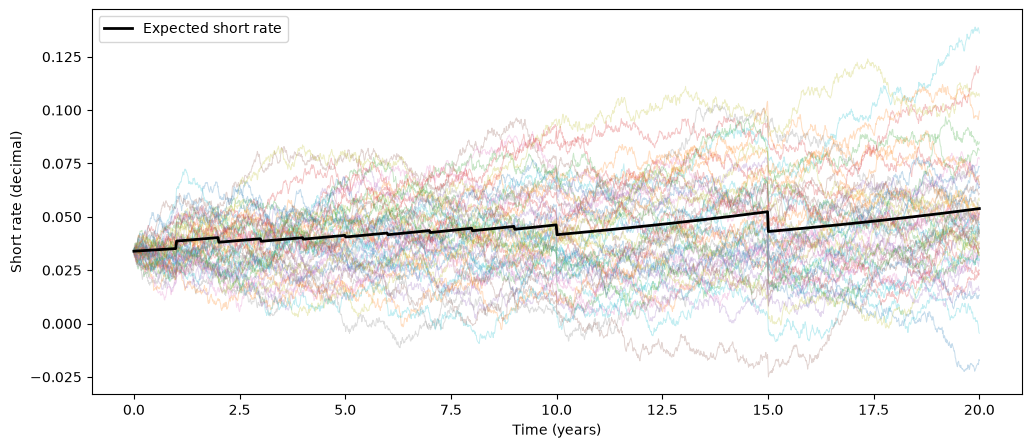

In [6]:
valuation_date = bond_prices.index[0]
obs = bond_prices.loc[valuation_date]
obs_curve = obs.dropna().copy()
obs_curve.loc[0.0] = 1.0
obs_curve = obs_curve.sort_index()

maturity_grid = np.linspace(0, obs_curve.index.max(), 2001)
a, sigma = 0.1, 0.01
r = simulate_short_rate(
    maturity_grid, obs_curve, a=a, sigma=sigma, n_paths=5000, seed=42
)
paths = pd.DataFrame(r, columns=maturity_grid)
phi_values = phi_vectorized(maturity_grid, obs_curve, sigma=sigma, a=a)

plt.figure(figsize=(12, 5))
plt.plot(maturity_grid, r[:50].T, alpha=0.25, linewidth=0.7)
plt.plot(maturity_grid, phi_values, color="black", linewidth=2,
         label="Expected short rate")
plt.xlabel("Time (years)")
plt.ylabel("Short rate (decimal)")
plt.legend()
plt.show()


# Sanity check

In [7]:
def bond_price_mc(T, paths_df):
    times = paths_df.columns.to_numpy(dtype=float)
    rates = paths_df.to_numpy(dtype=float)
    if times[0] != 0:
        raise ValueError("Paths must include time 0 to calculate B(0, T).")
    if not np.isfinite(T) or not 0 <= T <= times[-1]:
        raise ValueError("T is outside the simulated range.")
    if T == 0:
        return 1.0

    grid = np.r_[times[times < T], T]
    values = interp1d(times, rates, axis=1)(grid)
    integrals = trapezoid(values, x=grid, axis=1)
    return float(np.exp(-integrals).mean())


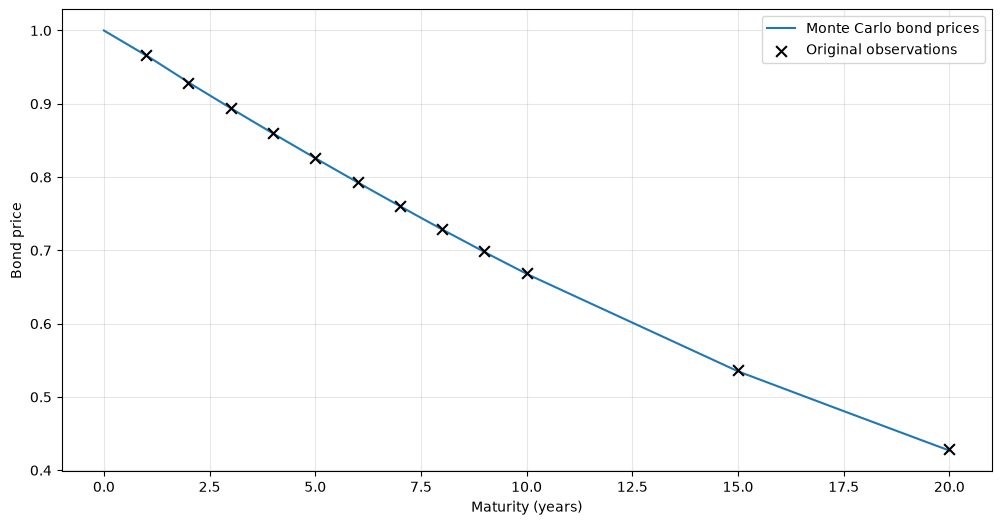

In [8]:
times = paths.columns.to_numpy(dtype=float)
rates = paths.to_numpy(dtype=float)
integrals = cumulative_trapezoid(rates, x=times, axis=1, initial=0)
mc_prices = np.exp(-integrals).mean(axis=0)
observations = obs.dropna().loc[times[0]:times[-1]]

plt.figure(figsize=(12, 6))
plt.plot(times, mc_prices, label="Monte Carlo bond prices")
plt.scatter(observations.index, observations, color="black", marker="x",
            s=60, label="Original observations", zorder=3)
plt.xlabel("Maturity (years)")
plt.ylabel("Bond price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
